In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report, 
                             confusion_matrix, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score)
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. LOAD DATA
# ============================================================
df = pd.read_csv('pulsar_stars.csv')

# Clean column names (they contain spaces)
df.columns = [c.strip() for c in df.columns]
print("Columns:", list(df.columns))
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df['target_class'].value_counts())
print(f"\nClass ratio (0:1) = {(df['target_class']==0).sum()}:{(df['target_class']==1).sum()}")

Columns: ['Mean of the integrated profile', 'Standard deviation of the integrated profile', 'Excess kurtosis of the integrated profile', 'Skewness of the integrated profile', 'Mean of the DM-SNR curve', 'Standard deviation of the DM-SNR curve', 'Excess kurtosis of the DM-SNR curve', 'Skewness of the DM-SNR curve', 'target_class']

Dataset shape: (17898, 9)

Class distribution:
target_class
0    16259
1     1639
Name: count, dtype: int64

Class ratio (0:1) = 16259:1639


Feature statistics:
                                                    mean         std  \
Mean of the integrated profile                111.079968   25.652935   
Standard deviation of the integrated profile   46.549532    6.843189   
Excess kurtosis of the integrated profile       0.477857    1.064040   
Skewness of the integrated profile              1.770279    6.167913   
Mean of the DM-SNR curve                       12.614400   29.472897   
Standard deviation of the DM-SNR curve         26.326515   19.470572   
Excess kurtosis of the DM-SNR curve             8.303556    4.506092   
Skewness of the DM-SNR curve                  104.857709  106.514540   

                                                    min          max  
Mean of the integrated profile                 5.812500   192.617188  
Standard deviation of the integrated profile  24.772042    98.778911  
Excess kurtosis of the integrated profile     -1.876011     8.069522  
Skewness of the integrated profile            -

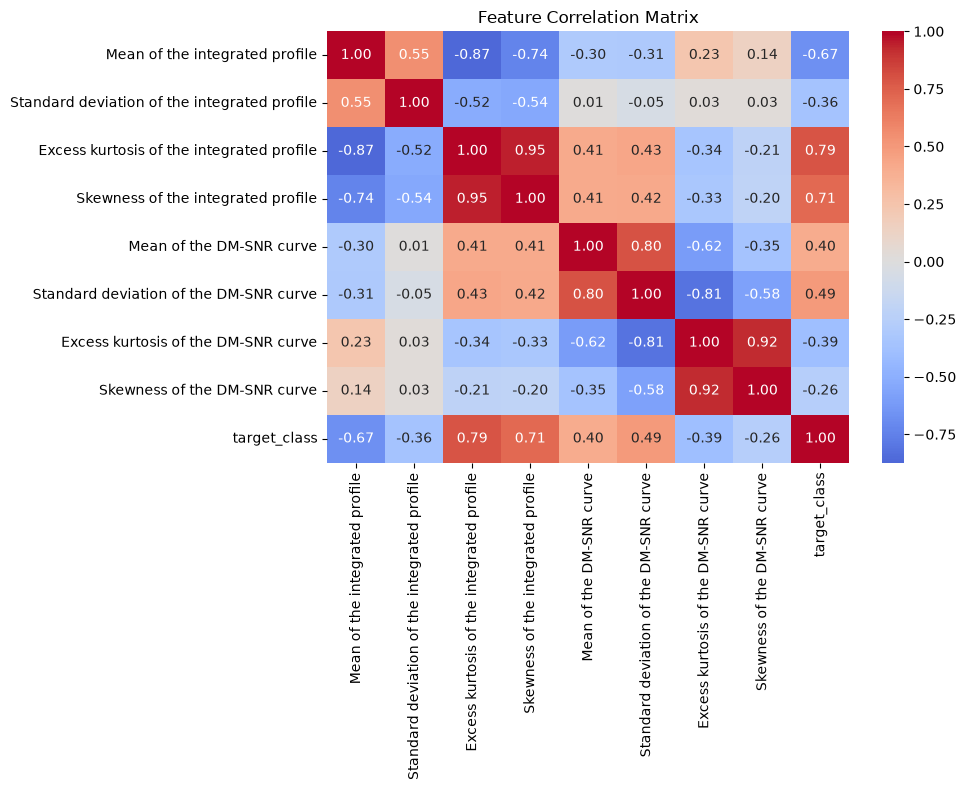

In [2]:
# ============================================================
# 2. EXPLORATORY DATA ANALYSIS
# ============================================================
X = df.drop('target_class', axis=1)
y = df['target_class']

# Statistical summary
print("Feature statistics:")
print(X.describe().T[['mean','std','min','max']])

# Check for missing values
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=100)
plt.show()

In [3]:
# ============================================================
# 3. TRAIN-TEST SPLIT (stratified to preserve imbalance)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class distribution:\n{y_train.value_counts()}")

# ============================================================
# 4. FEATURE SCALING (critical for SVM)
# ============================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================
# 5. BASELINE SVM (RBF kernel, default params)
# ============================================================
svm_baseline = SVC(kernel='rbf', random_state=42)
svm_baseline.fit(X_train_scaled, y_train)
y_pred_base = svm_baseline.predict(X_test_scaled)

print("\n=== Baseline SVM (RBF, default) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_base):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_base):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_base):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, svm_baseline.decision_function(X_test_scaled)):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_base, target_names=['Non-Pulsar','Pulsar']))

Train: (14318, 8), Test: (3580, 8)
Train class distribution:
target_class
0    13007
1     1311
Name: count, dtype: int64

=== Baseline SVM (RBF, default) ===
Accuracy:  0.9807
Precision: 0.9481
Recall:    0.8354
F1-score:  0.8882
ROC-AUC:   0.9542

Classification Report:
              precision    recall  f1-score   support

  Non-Pulsar       0.98      1.00      0.99      3252
      Pulsar       0.95      0.84      0.89       328

    accuracy                           0.98      3580
   macro avg       0.97      0.92      0.94      3580
weighted avg       0.98      0.98      0.98      3580



In [4]:
# ============================================================
# 6. HANDLING CLASS IMBALANCE
# ============================================================
# Compare class_weight strategies

results_imbalance = {}
for strategy in [None, 'balanced']:
    svm = SVC(kernel='rbf', class_weight=strategy, random_state=42)
    svm.fit(X_train_scaled, y_train)
    y_pred = svm.predict(X_test_scaled)
    results_imbalance[str(strategy)] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, svm.decision_function(X_test_scaled))
    }

print("\n=== Class Weight Comparison ===")
print(pd.DataFrame(results_imbalance).T.round(4))


=== Class Weight Comparison ===
          Accuracy  Precision  Recall      F1  ROC-AUC
None        0.9807     0.9481  0.8354  0.8882   0.9542
balanced    0.9718     0.8043  0.9146  0.8559   0.9661


In [5]:
# ============================================================
# 7. HYPERPARAMETER TUNING (GridSearchCV)
# ============================================================
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1],
    'kernel': ['rbf']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    SVC(class_weight='balanced', random_state=42),
    param_grid,
    cv=cv,
    scoring='f1',      # F1 is better than accuracy for imbalanced data
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train_scaled, y_train)

print("\nBest parameters:", grid.best_params_)
print(f"Best CV F1-score: {grid.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best parameters: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV F1-score: 0.8713



=== Tuned SVM (Best Model) ===
Accuracy:  0.9757
Precision: 0.8375
Recall:    0.9116
F1-score:  0.8730
ROC-AUC:   0.9724

              precision    recall  f1-score   support

  Non-Pulsar       0.99      0.98      0.99      3252
      Pulsar       0.84      0.91      0.87       328

    accuracy                           0.98      3580
   macro avg       0.91      0.95      0.93      3580
weighted avg       0.98      0.98      0.98      3580



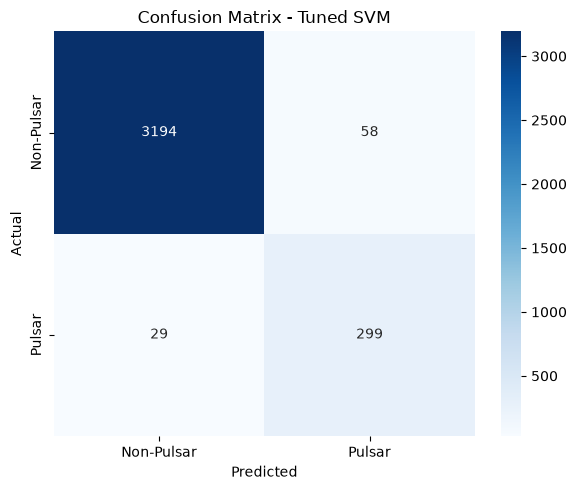

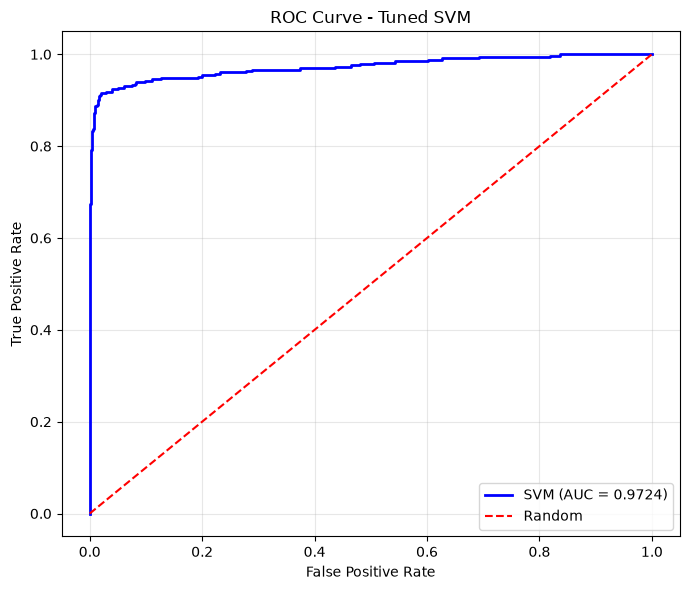

In [6]:
# ============================================================
# 8. FINAL MODEL EVALUATION
# ============================================================
best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test_scaled)
y_scores = best_svm.decision_function(X_test_scaled)

print("\n=== Tuned SVM (Best Model) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_scores):.4f}")
print("\n" + classification_report(y_test, y_pred, target_names=['Non-Pulsar','Pulsar']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Pulsar','Pulsar'],
            yticklabels=['Non-Pulsar','Pulsar'])
plt.title('Confusion Matrix - Tuned SVM')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=100)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, 'b-', linewidth=2, label=f'SVM (AUC = {auc:.4f})')
plt.plot([0,1], [0,1], 'r--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned SVM')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=100)
plt.show()


=== Kernel Comparison ===
         Accuracy  Precision  Recall      F1  ROC-AUC
Kernel                                               
linear     0.9749     0.8269  0.9177  0.8699   0.9708
poly       0.9757     0.8473  0.8963  0.8711   0.9618
rbf        0.9718     0.8043  0.9146  0.8559   0.9661
sigmoid    0.8128     0.3070  0.8293  0.4481   0.8664


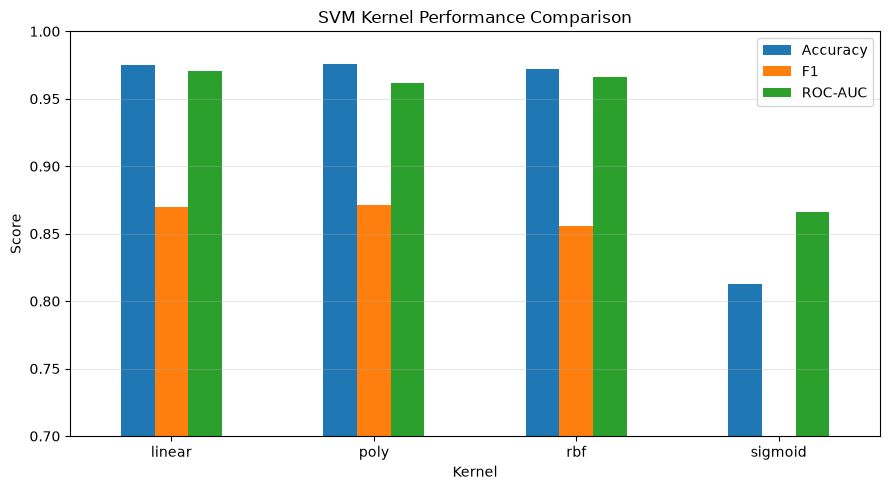

In [7]:
# ============================================================
# 9. KERNEL COMPARISON
# ============================================================
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
kernel_results = []

for k in kernels:
    svm = SVC(kernel=k, class_weight='balanced', random_state=42)
    svm.fit(X_train_scaled, y_train)
    y_pred = svm.predict(X_test_scaled)
    kernel_results.append({
        'Kernel': k,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, svm.decision_function(X_test_scaled))
    })

kernel_df = pd.DataFrame(kernel_results).set_index('Kernel')
print("\n=== Kernel Comparison ===")
print(kernel_df.round(4))

kernel_df[['Accuracy','F1','ROC-AUC']].plot(kind='bar', figsize=(9,5))
plt.title('SVM Kernel Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0.7, 1.0)
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('kernel_comparison.png', dpi=100)
plt.show()

In [8]:
# ============================================================
# 10. PCA + SVM (Dimensionality Reduction Experiment)
# ============================================================
pca = PCA(n_components=0.95)  # keep 95% variance
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"\nOriginal features: {X_train_scaled.shape[1]}")
print(f"PCA components (95% variance): {X_train_pca.shape[1]}")
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.4f}")

svm_pca = SVC(kernel='rbf', C=10, class_weight='balanced', random_state=42)
svm_pca.fit(X_train_pca, y_train)
y_pred_pca = svm_pca.predict(X_test_pca)

print(f"\nPCA+SVM Accuracy: {accuracy_score(y_test, y_pred_pca):.4f}")
print(f"PCA+SVM F1:       {f1_score(y_test, y_pred_pca):.4f}")


Original features: 8
PCA components (95% variance): 5
Explained variance: 0.9758

PCA+SVM Accuracy: 0.9726
PCA+SVM F1:       0.8584
